In [1]:
import pandas as pd
df = pd.read_csv('./Crop_recommendation.csv')
print(df.shape)
df.head()

(2200, 8)


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 137.6 KB


In [3]:
df.describe()


,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


In [4]:
df.isnull().sum()

N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

In [5]:
df['label'].value_counts()

label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

# Separate features and target
X = df.drop('label', axis=1)
y = df['label']

# Split: 60% train, 20% val, 20% test
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (1320, 7)
Validation: (440, 7)
Test: (440, 7)


In [7]:
configs = [
    {'max_depth': 5, 'criterion': 'entropy'},
    {'max_depth': 10, 'criterion': 'entropy'},
    {'max_depth': None, 'criterion': 'entropy'},  # None = no depth limit, grows fully
]

results = []

for cfg in configs:
    model = DecisionTreeClassifier(**cfg, random_state=42)
    model.fit(X_train, y_train)
    val_preds = model.predict(X_val)
    
    acc = accuracy_score(y_val, val_preds)
    precision, recall, f1, _ = precision_recall_fscore_support(y_val, val_preds, average='macro')
    
    results.append({
        'config': cfg,
        'accuracy': acc,
        'precision': precision,
        'recall': recall,
        'f1': f1
    })
    print(cfg)
    print(f"  Accuracy: {acc:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}, F1: {f1:.4f}")
    print()

{'max_depth': 5, 'criterion': 'entropy'}
  Accuracy: 0.9068, Precision: 0.9280, Recall: 0.9068, F1: 0.8980

{'max_depth': 10, 'criterion': 'entropy'}
  Accuracy: 0.9705, Precision: 0.9711, Recall: 0.9705, F1: 0.9706

{'max_depth': None, 'criterion': 'entropy'}
  Accuracy: 0.9705, Precision: 0.9711, Recall: 0.9705, F1: 0.9706



In [8]:
final_model = DecisionTreeClassifier(max_depth=10, criterion='entropy', random_state=42)
final_model.fit(X_train, y_train)

test_preds = final_model.predict(X_test)

test_acc = accuracy_score(y_test, test_preds)
test_precision, test_recall, test_f1, _ = precision_recall_fscore_support(y_test, test_preds, average='macro')

print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Precision: {test_precision:.4f}")
print(f"Test Recall: {test_recall:.4f}")
print(f"Test F1: {test_f1:.4f}")

Test Accuracy: 0.9727
Test Precision: 0.9742
Test Recall: 0.9727
Test F1: 0.9729


In [9]:
import pandas as pd

# Build comparison table from results
comparison_data = []
for r in results:
    comparison_data.append({
        'Model/Configuration': str(r['config']),
        'Accuracy': round(r['accuracy'], 4),
        'Precision': round(r['precision'], 4),
        'Recall': round(r['recall'], 4),
        'F1': round(r['f1'], 4)
    })

# Add the final selected model's test performance (run test eval first if you haven't)
comparison_data.append({
    'Model/Configuration': 'Selected Model (max_depth=10, entropy) - TEST SET',
    'Accuracy': round(test_acc, 4),
    'Precision': round(test_precision, 4),
    'Recall': round(test_recall, 4),
    'F1': round(test_f1, 4)
})

comparison_df = pd.DataFrame(comparison_data)
comparison_df

,Model/Configuration,Accuracy,Precision,Recall,F1
0,"{'max_depth': 5, 'criterion': 'entropy'}",0.9068,0.9280,0.9068,0.8980
1,"{'max_depth': 10, 'criterion': 'entropy'}",0.9705,0.9711,0.9705,0.9706
2,"{'max_depth': None, 'criterion': 'entropy'}",0.9705,0.9711,0.9705,0.9706
3,"Selected Model (max_depth=10, entropy) - TEST SET",0.9727,0.9742,0.9727,0.9729


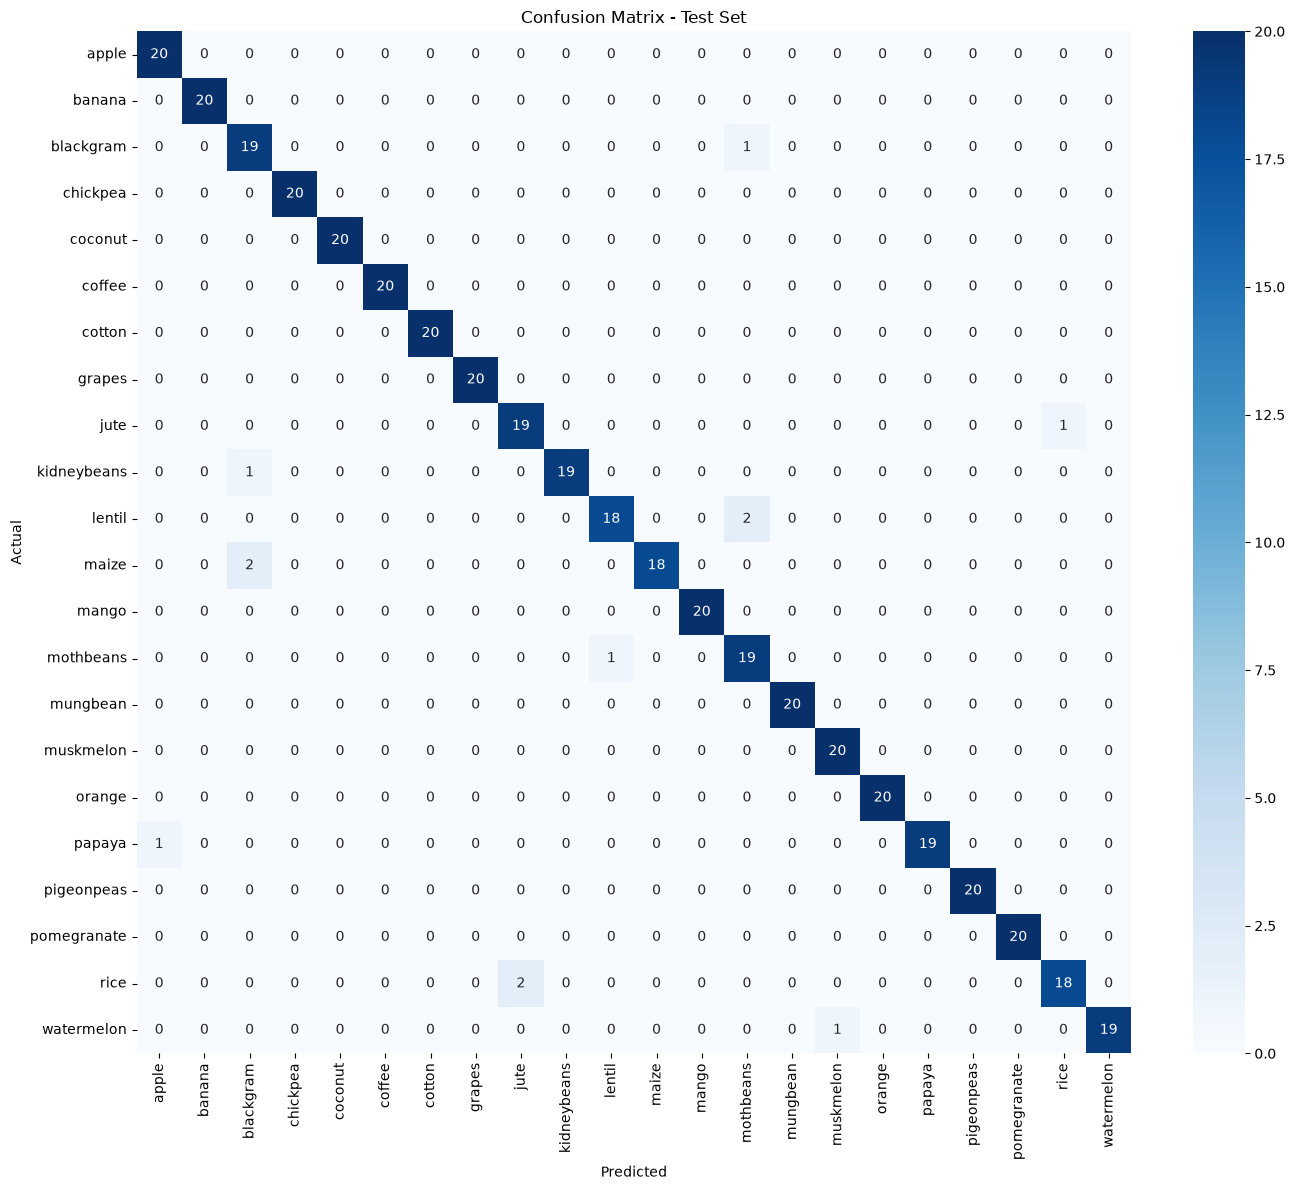

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, test_preds, labels=final_model.classes_)

plt.figure(figsize=(14, 12))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=final_model.classes_, yticklabels=final_model.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Test Set')
plt.tight_layout()
plt.show()

In [11]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_auc_score

y_test_bin = label_binarize(y_test, classes=final_model.classes_)
y_proba = final_model.predict_proba(X_test)
roc_auc = roc_auc_score(y_test_bin, y_proba, average='macro', multi_class='ovr')
print(f"Macro ROC-AUC: {roc_auc:.4f}")

Macro ROC-AUC: 0.9857


In [12]:
# Find misclassified rows
misclassified_mask = y_test.values != test_preds
X_test_misclassified = X_test[misclassified_mask]
y_actual_misclassified = y_test[misclassified_mask]
y_predicted_misclassified = test_preds[misclassified_mask]

misclassified_df = X_test_misclassified.copy()
misclassified_df['Actual'] = y_actual_misclassified.values
misclassified_df['Predicted'] = y_predicted_misclassified

misclassified_df

,N,P,K,temperature,humidity,ph,rainfall,Actual,Predicted
2018,82,35,44,26.966564,78.210477,6.239011,169.839118,jute,rice
768,23,57,19,32.839638,67.998036,7.251001,73.404527,blackgram,mothbeans
852,12,58,23,21.746001,63.395032,6.765091,50.433061,lentil,mothbeans
838,31,58,15,28.318869,60.194614,6.167855,45.365213,lentil,mothbeans
1343,107,5,52,26.663461,89.984052,6.881426,57.408472,watermelon,muskmelon
1733,39,70,52,26.265595,90.796681,6.651491,59.493734,papaya,apple
114,66,54,21,25.190087,60.200169,5.919046,72.123756,maize,blackgram
363,37,74,15,24.923601,18.225908,5.582178,62.708917,kidneybeans,blackgram
575,27,59,20,28.009374,52.609500,4.397699,36.012030,mothbeans,lentil
185,88,38,15,25.082397,65.921958,6.455117,62.491908,maize,blackgram


In [13]:
import numpy as np

sample_indices = [0, 50, 100]
samples = X_test.iloc[sample_indices].copy()
actual_labels = y_test.iloc[sample_indices].values

sensitivity_results = []
features_to_test = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

for idx, (i, row) in enumerate(samples.iterrows()):
    original_pred = final_model.predict(pd.DataFrame([row]))[0]
    
    for feature in features_to_test:
        modified_row = row.copy()
        original_value = modified_row[feature]
        
        modified_row[feature] = original_value * 1.2
        new_pred_increase = final_model.predict(pd.DataFrame([modified_row]))[0]
        
        modified_row[feature] = original_value * 0.8
        new_pred_decrease = final_model.predict(pd.DataFrame([modified_row]))[0]
        
        sensitivity_results.append({
            'Sample': f'Sample {idx+1} (actual: {actual_labels[idx]})',
            'Feature': feature,
            'Original Value': round(original_value, 2),
            'Original Prediction': original_pred,
            'Prediction (+20%)': new_pred_increase,
            'Changed (+20%)?': 'YES' if new_pred_increase != original_pred else 'No',
            'Prediction (-20%)': new_pred_decrease,
            'Changed (-20%)?': 'YES' if new_pred_decrease != original_pred else 'No',
        })

sensitivity_df = pd.DataFrame(sensitivity_results)
sensitivity_df

,Sample,Feature,Original Value,Original Prediction,Prediction (+20%),Changed (+20%)?,Prediction (-20%),Changed (-20%)?
0,Sample 1 (actual: pigeonpeas),N,33.00,pigeonpeas,pigeonpeas,No,pigeonpeas,No
1,Sample 1 (actual: pigeonpeas),P,73.00,pigeonpeas,pigeonpeas,No,pigeonpeas,No
2,Sample 1 (actual: pigeonpeas),K,23.00,pigeonpeas,chickpea,YES,pigeonpeas,No
3,Sample 1 (actual: pigeonpeas),temperature,29.24,pigeonpeas,pigeonpeas,No,pigeonpeas,No
4,Sample 1 (actual: pigeonpeas),humidity,59.39,pigeonpeas,pigeonpeas,No,pigeonpeas,No
5,Sample 1 (actual: pigeonpeas),ph,5.99,pigeonpeas,pigeonpeas,No,pigeonpeas,No
6,Sample 1 (actual: pigeonpeas),rainfall,103.33,pigeonpeas,pigeonpeas,No,pigeonpeas,No
7,Sample 2 (actual: orange),N,12.00,orange,orange,No,orange,No
8,Sample 2 (actual: orange),P,29.00,orange,mungbean,YES,orange,No
9,Sample 2 (actual: orange),K,13.00,orange,orange,No,orange,No


In [14]:
from sklearn.tree import export_text

tree_rules = export_text(final_model, feature_names=list(X_train.columns))
print(tree_rules)

|--- humidity <= 74.86
|   |--- K <= 25.50
|   |   |--- rainfall <= 74.97
|   |   |   |--- rainfall <= 59.28
|   |   |   |   |--- P <= 58.50
|   |   |   |   |   |--- humidity <= 65.28
|   |   |   |   |   |   |--- class: mothbeans
|   |   |   |   |   |--- humidity >  65.28
|   |   |   |   |   |   |--- class: lentil
|   |   |   |   |--- P >  58.50
|   |   |   |   |   |--- class: lentil
|   |   |   |--- rainfall >  59.28
|   |   |   |   |--- temperature <= 24.86
|   |   |   |   |   |--- humidity <= 40.10
|   |   |   |   |   |   |--- class: kidneybeans
|   |   |   |   |   |--- humidity >  40.10
|   |   |   |   |   |   |--- class: maize
|   |   |   |   |--- temperature >  24.86
|   |   |   |   |   |--- P <= 57.50
|   |   |   |   |   |   |--- N <= 40.50
|   |   |   |   |   |   |   |--- class: mothbeans
|   |   |   |   |   |   |--- N >  40.50
|   |   |   |   |   |   |   |--- rainfall <= 72.25
|   |   |   |   |   |   |   |   |--- class: blackgram
|   |   |   |   |   |   |   |--- rainfall >  72

In [15]:
from sklearn.tree import _tree

def get_rules(tree, feature_names, class_names):
    tree_ = tree.tree_
    feature_name = [
        feature_names[i] if i != _tree.TREE_UNDEFINED else "undefined!"
        for i in tree_.feature
    ]
    
    paths = []
    
    def recurse(node, path):
        if tree_.feature[node] != _tree.TREE_UNDEFINED:
            name = feature_name[node]
            threshold = tree_.threshold[node]
            
            # Left branch (<=)
            recurse(tree_.children_left[node], path + [f"{name} <= {threshold:.2f}"])
            # Right branch (>)
            recurse(tree_.children_right[node], path + [f"{name} > {threshold:.2f}"])
        else:
            # Leaf node - get predicted class
            class_idx = tree_.value[node].argmax()
            predicted_class = class_names[class_idx]
            paths.append((path, predicted_class, len(path)))
    
    recurse(0, [])
    return paths

rules = get_rules(final_model, list(X_train.columns), final_model.classes_)

# Sort by path length to find shortest and longest
rules_sorted = sorted(rules, key=lambda x: x[2])

print("=== SHORTEST RULE ===")
shortest = rules_sorted[0]
print(f"IF {' AND '.join(shortest[0])} THEN crop = {shortest[1]}")
print(f"(Path length: {shortest[2]})\n")

print("=== LONGEST RULE ===")
longest = rules_sorted[-1]
print(f"IF {' AND '.join(longest[0])} THEN crop = {longest[1]}")
print(f"(Path length: {longest[2]})\n")

print("=== 5 SAMPLE RULES ===")
import random
random.seed(42)
sample_rules = random.sample(rules, min(5, len(rules)))
for path, pred_class, length in sample_rules:
    print(f"IF {' AND '.join(path)} THEN crop = {pred_class}")
    print()

=== SHORTEST RULE ===
IF humidity <= 74.86 AND K <= 25.50 AND rainfall > 74.97 AND humidity <= 27.98 THEN crop = kidneybeans
(Path length: 4)

=== LONGEST RULE ===
IF humidity > 74.86 AND P > 32.50 AND P <= 69.00 AND K > 30.00 AND humidity <= 89.95 AND rainfall <= 197.67 AND ph > 5.99 AND temperature > 22.89 AND P > 36.50 AND N > 98.50 THEN crop = jute
(Path length: 10)

=== 5 SAMPLE RULES ===
IF humidity <= 74.86 AND K <= 25.50 AND rainfall <= 74.97 AND rainfall > 59.28 AND temperature > 24.86 AND P <= 57.50 AND N > 40.50 AND rainfall > 72.25 THEN crop = maize

IF humidity <= 74.86 AND K <= 25.50 AND rainfall <= 74.97 AND rainfall <= 59.28 AND P <= 58.50 AND humidity > 65.28 THEN crop = lentil

IF humidity <= 74.86 AND K > 25.50 AND N > 62.00 AND humidity <= 70.42 THEN crop = coffee

IF humidity <= 74.86 AND K > 25.50 AND N <= 62.00 AND P <= 47.50 THEN crop = mango

IF humidity <= 74.86 AND K <= 25.50 AND rainfall > 74.97 AND humidity > 27.98 AND N > 50.00 AND rainfall > 117.08 THEN c

In [16]:
# Test rule 5: humidity > 74.86, P > 69, humidity > 87.50 → apple
test_case = pd.DataFrame([{
    'N': 20, 'P': 75, 'K': 200, 'temperature': 22, 
    'humidity': 92, 'ph': 6.0, 'rainfall': 110
}])
prediction = final_model.predict(test_case)[0]
print(f"Predicted crop: {prediction}")

Predicted crop: apple


C:\Users\krish\AppData\Local\Temp\ipykernel_7356\2911964640.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df, x='Importance', y='Feature', palette='viridis')


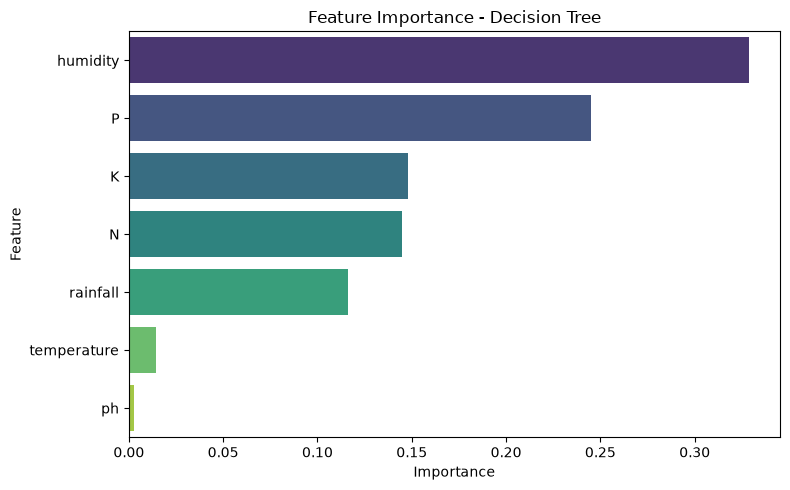

,Feature,Importance
4,humidity,0.328781
1,P,0.245199
2,K,0.147824
0,N,0.144866
6,rainfall,0.116446
3,temperature,0.014333
5,ph,0.002550


In [17]:
importances = final_model.feature_importances_
feature_names = X_train.columns

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=importance_df, x='Importance', y='Feature', palette='viridis')
plt.title('Feature Importance - Decision Tree')
plt.tight_layout()
plt.show()

importance_df

In [21]:
X_train.to_csv('data/X_train.csv', index=False)
X_val.to_csv('data/X_val.csv', index=False)
X_test.to_csv('data/X_test.csv', index=False)
y_train.to_csv('data/y_train.csv', index=False)
y_val.to_csv('data/y_val.csv', index=False)
y_test.to_csv('data/y_test.csv', index=False)